In [3]:
!pip install "numpy<2" --force-reinstall --break-system-packages

  You can safely remove it manually.
  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gensim 4.3.3 requires scipy<1.14.0,>=1.7.0, but you have scipy 1.17.1 which is incompatible.
shap 0.52.0 requires numpy>=2, but you have numpy 1.26.4 which is incompatible.
streamlit 1.37.1 requires packaging<25,>=20, but you have packaging 26.2 which is incompatible.
streamlit 1.37.1 requires pandas<3,>=1.3.0, but you have pandas 3.0.5 which is incompatible.


  Using cached numpy-1.26.4-cp312-cp312-win_amd64.whl.metadata (61 kB)
Using cached numpy-1.26.4-cp312-cp312-win_amd64.whl (15.5 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:
      Successfully uninstalled numpy-1.26.4
  Using cached numpy-1.26.4-cp312-cp312-win_amd64.whl.metadata (61 kB)
Using cached numpy-1.26.4-cp312-cp312-win_amd64.whl (15.5 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:
      Successfully uninstalled numpy-1.26.4


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gensim 4.3.3 requires scipy<1.14.0,>=1.7.0, but you have scipy 1.17.1 which is incompatible.
shap 0.52.0 requires numpy>=2, but you have numpy 1.26.4 which is incompatible.
streamlit 1.37.1 requires packaging<25,>=20, but you have packaging 26.2 which is incompatible.
streamlit 1.37.1 requires pandas<3,>=1.3.0, but you have pandas 3.0.5 which is incompatible.


In [4]:
import pandas as pd

In [5]:
import numpy as np

In [6]:
df= pd.read_csv('application_train.csv')

In [7]:
df.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [8]:
df.shape

(307511, 122)

In [9]:
df['TARGET'].value_counts(normalize=True)

TARGET
0    0.919271
1    0.080729
Name: proportion, dtype: float64

In [10]:
df.isnull().sum().sort_values(ascending= False).head(10)

COMMONAREA_MEDI             214865
COMMONAREA_AVG              214865
COMMONAREA_MODE             214865
NONLIVINGAPARTMENTS_MODE    213514
NONLIVINGAPARTMENTS_AVG     213514
NONLIVINGAPARTMENTS_MEDI    213514
FONDKAPREMONT_MODE          210295
LIVINGAPARTMENTS_MODE       210199
LIVINGAPARTMENTS_AVG        210199
LIVINGAPARTMENTS_MEDI       210199
dtype: int64

In [11]:
missing_pct= (df.isnull().sum()/ len(df))*100
missing_pct[missing_pct>0].sort_values(ascending= False)

COMMONAREA_MEDI             69.872297
COMMONAREA_AVG              69.872297
COMMONAREA_MODE             69.872297
NONLIVINGAPARTMENTS_MEDI    69.432963
NONLIVINGAPARTMENTS_MODE    69.432963
                              ...    
EXT_SOURCE_2                 0.214626
AMT_GOODS_PRICE              0.090403
AMT_ANNUITY                  0.003902
CNT_FAM_MEMBERS              0.000650
DAYS_LAST_PHONE_CHANGE       0.000325
Length: 67, dtype: float64

In [12]:
df.columns

Index(['SK_ID_CURR', 'TARGET', 'NAME_CONTRACT_TYPE', 'CODE_GENDER',
       'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL',
       'AMT_CREDIT', 'AMT_ANNUITY',
       ...
       'FLAG_DOCUMENT_18', 'FLAG_DOCUMENT_19', 'FLAG_DOCUMENT_20',
       'FLAG_DOCUMENT_21', 'AMT_REQ_CREDIT_BUREAU_HOUR',
       'AMT_REQ_CREDIT_BUREAU_DAY', 'AMT_REQ_CREDIT_BUREAU_WEEK',
       'AMT_REQ_CREDIT_BUREAU_MON', 'AMT_REQ_CREDIT_BUREAU_QRT',
       'AMT_REQ_CREDIT_BUREAU_YEAR'],
      dtype='str', length=122)

In [13]:
cols_to_drop=missing_pct[missing_pct>40].index
len(cols_to_drop)

49

In [14]:
df=df.drop(columns=cols_to_drop)

In [15]:
df.shape

(307511, 73)

In [16]:
numeric_cols= df.select_dtypes(include=['Float64','Int64']).columns
categorical_cols=df.select_dtypes(include=['object']).columns

C:\Users\91991\AppData\Local\Temp\ipykernel_6616\1132050969.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols=df.select_dtypes(include=['object']).columns


In [17]:
len(numeric_cols), len(categorical_cols)

(61, 12)

In [18]:
df[numeric_cols]= df[numeric_cols].fillna(df[numeric_cols].median())
for col in categorical_cols: df[col]=df[col].fillna(df[col].mode()[0])

In [19]:
df.isnull().sum().sum()

0

In [20]:
df.isnull().sum()[df.isnull().sum() > 0]

Series([], dtype: int64)

In [21]:
df['OCCUPATION_TYPE'].dtype

<StringDtype(na_value=nan)>

In [22]:
'OCCUPATIONAL_TYPE' in categorical_cols

False

In [23]:
df.isnull().sum().sum()

0

In [24]:
for col in categorical_cols:
    print(col, df[col].isnull().sum())

NAME_CONTRACT_TYPE 0
CODE_GENDER 0
FLAG_OWN_CAR 0
FLAG_OWN_REALTY 0
NAME_TYPE_SUITE 0
NAME_INCOME_TYPE 0
NAME_EDUCATION_TYPE 0
NAME_FAMILY_STATUS 0
NAME_HOUSING_TYPE 0
OCCUPATION_TYPE 0
WEEKDAY_APPR_PROCESS_START 0
ORGANIZATION_TYPE 0


In [25]:
df['OCCUPATION_TYPE'].mode()

0    Laborers
Name: OCCUPATION_TYPE, dtype: str

In [26]:
df.isnull().sum().sum()

0

In [27]:
df['DAYS_EMPLOYED']

0           -637
1          -1188
2           -225
3          -3039
4          -3038
           ...  
307506      -236
307507    365243
307508     -7921
307509     -4786
307510     -1262
Name: DAYS_EMPLOYED, Length: 307511, dtype: int64

In [28]:
df['AGE']=(-df['DAYS_BIRTH'])/365

In [29]:
df['EMPLOYEE_YEARS']=(-df['DAYS_EMPLOYED'])/365

In [30]:
df['DAYS_EMPLOYED'].describe()

count    307511.000000
mean      63815.045904
std      141275.766519
min      -17912.000000
25%       -2760.000000
50%       -1213.000000
75%        -289.000000
max      365243.000000
Name: DAYS_EMPLOYED, dtype: float64

In [31]:
df['NOT_EMPLOYED']=(df['DAYS_EMPLOYED']==365243).astype(int)
df['DAYS_EMPLOYED']=df['DAYS_EMPLOYED'].replace(365243, np.NaN)
df['EMPLOYEE_YEARS']=(-df['DAYS_EMPLOYED'])/365

In [32]:
df['DAYS_EMPLOYED'].describe()

count    252137.000000
mean      -2384.169325
std        2338.360162
min      -17912.000000
25%       -3175.000000
50%       -1648.000000
75%        -767.000000
max           0.000000
Name: DAYS_EMPLOYED, dtype: float64

In [33]:
df['EMPLOYEE_YEARS'].describe()

count    252137.000000
mean          6.531971
std           6.406466
min          -0.000000
25%           2.101370
50%           4.515068
75%           8.698630
max          49.073973
Name: EMPLOYEE_YEARS, dtype: float64

In [34]:
df['DEBT_TO_INCOME']= df['AMT_CREDIT']/df['AMT_INCOME_TOTAL']
df['INCOME_PER_PERSON']=df['AMT_INCOME_TOTAL']/df['CNT_FAM_MEMBERS']
df['CREDIT_TO_ANNUITY']=df['AMT_CREDIT']/df['AMT_ANNUITY']

In [35]:
for col in categorical_cols:
    print(col, df[col].nunique())

NAME_CONTRACT_TYPE 2
CODE_GENDER 3
FLAG_OWN_CAR 2
FLAG_OWN_REALTY 2
NAME_TYPE_SUITE 7
NAME_INCOME_TYPE 8
NAME_EDUCATION_TYPE 5
NAME_FAMILY_STATUS 6
NAME_HOUSING_TYPE 6
OCCUPATION_TYPE 18
WEEKDAY_APPR_PROCESS_START 7
ORGANIZATION_TYPE 58


In [36]:
df['NAME_FAMILY_STATUS']

0         Single / not married
1                      Married
2         Single / not married
3               Civil marriage
4         Single / not married
                  ...         
307506               Separated
307507                   Widow
307508               Separated
307509                 Married
307510                 Married
Name: NAME_FAMILY_STATUS, Length: 307511, dtype: str

In [37]:
df = pd.get_dummies(df, columns=categorical_cols, drop_first=True)



In [38]:
df.shape

(307511, 179)

In [39]:
df.columns.tolist()

['SK_ID_CURR',
 'TARGET',
 'CNT_CHILDREN',
 'AMT_INCOME_TOTAL',
 'AMT_CREDIT',
 'AMT_ANNUITY',
 'AMT_GOODS_PRICE',
 'REGION_POPULATION_RELATIVE',
 'DAYS_BIRTH',
 'DAYS_EMPLOYED',
 'DAYS_REGISTRATION',
 'DAYS_ID_PUBLISH',
 'FLAG_MOBIL',
 'FLAG_EMP_PHONE',
 'FLAG_WORK_PHONE',
 'FLAG_CONT_MOBILE',
 'FLAG_PHONE',
 'FLAG_EMAIL',
 'CNT_FAM_MEMBERS',
 'REGION_RATING_CLIENT',
 'REGION_RATING_CLIENT_W_CITY',
 'HOUR_APPR_PROCESS_START',
 'REG_REGION_NOT_LIVE_REGION',
 'REG_REGION_NOT_WORK_REGION',
 'LIVE_REGION_NOT_WORK_REGION',
 'REG_CITY_NOT_LIVE_CITY',
 'REG_CITY_NOT_WORK_CITY',
 'LIVE_CITY_NOT_WORK_CITY',
 'EXT_SOURCE_2',
 'EXT_SOURCE_3',
 'OBS_30_CNT_SOCIAL_CIRCLE',
 'DEF_30_CNT_SOCIAL_CIRCLE',
 'OBS_60_CNT_SOCIAL_CIRCLE',
 'DEF_60_CNT_SOCIAL_CIRCLE',
 'DAYS_LAST_PHONE_CHANGE',
 'FLAG_DOCUMENT_2',
 'FLAG_DOCUMENT_3',
 'FLAG_DOCUMENT_4',
 'FLAG_DOCUMENT_5',
 'FLAG_DOCUMENT_6',
 'FLAG_DOCUMENT_7',
 'FLAG_DOCUMENT_8',
 'FLAG_DOCUMENT_9',
 'FLAG_DOCUMENT_10',
 'FLAG_DOCUMENT_11',
 'FLAG_DOCUMEN

In [40]:
df['DAYS_EMPLOYED']=df['DAYS_EMPLOYED'].fillna(df['DAYS_EMPLOYED'].median())
df['EMPLOYEE_YEARS']=df['EMPLOYEE_YEARS'].fillna(df['EMPLOYEE_YEARS'].median())

In [41]:
from sklearn.model_selection import train_test_split
X= df.drop(columns=['SK_ID_CURR','TARGET'])
Y=df['TARGET']
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, stratify=Y, random_state=45 )
print(X_train.shape, X_test.shape)

(246008, 177) (61503, 177)


how do we know what column to delete, is it because target was the final answer so we deleted that? we used to different what, data frames X and Y.....we deleted 2 from X and kept only target in Y?...we created 4 more things....x y train and test...what are these, columns? dataframe? they all r calculated using one code......how? won't the answer be same...ohk wait it will differ on the basis of x and y......ohk but the rest...i am confused

X has null values so we are gonna fix that by replacing teh nan with their medians

In [42]:
X_train.isnull().sum()[X_train.isnull().sum()>0]

Series([], dtype: int64)

In [43]:
df.isnull().sum().sum()

0

In [44]:
X_test.isnull().sum()[X_test.isnull().sum()>0]

Series([], dtype: int64)

In [45]:
df.isnull().sum().sum()
X= df.drop(columns=['SK_ID_CURR','TARGET'])
Y= df['TARGET']
X_train, X_test, Y_train, Y_test= train_test_split(X, Y, test_size=0.2, stratify=Y,random_state=42)
print(X_test.isnull().sum(), X_train.isnull().sum())

CNT_CHILDREN                           0
AMT_INCOME_TOTAL                       0
AMT_CREDIT                             0
AMT_ANNUITY                            0
AMT_GOODS_PRICE                        0
                                      ..
ORGANIZATION_TYPE_Transport: type 2    0
ORGANIZATION_TYPE_Transport: type 3    0
ORGANIZATION_TYPE_Transport: type 4    0
ORGANIZATION_TYPE_University           0
ORGANIZATION_TYPE_XNA                  0
Length: 177, dtype: int64 CNT_CHILDREN                           0
AMT_INCOME_TOTAL                       0
AMT_CREDIT                             0
AMT_ANNUITY                            0
AMT_GOODS_PRICE                        0
                                      ..
ORGANIZATION_TYPE_Transport: type 2    0
ORGANIZATION_TYPE_Transport: type 3    0
ORGANIZATION_TYPE_Transport: type 4    0
ORGANIZATION_TYPE_University           0
ORGANIZATION_TYPE_XNA                  0
Length: 177, dtype: int64


In [46]:
from sklearn.linear_model import LogisticRegression
log_reg=LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train, Y_train)

c:\Users\91991\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lb

In [47]:
Y_pred_prob= log_reg.predict_proba(X_test)[:,1]

In [48]:
comparison= pd.DataFrame({'actual': Y_test,'prediction': Y_pred_prob})
comparison.head(10)

,actual,prediction
256571,0,0.085137
191493,0,0.063930
103497,0,0.083955
130646,0,0.118682
211898,0,0.099569
130549,0,0.111528
287975,0,0.024973
144906,0,0.049663
102173,0,0.119881
254495,1,0.071514


In [49]:
len(Y_test), len(Y_train), len(Y_pred_prob)

(61503, 246008, 61503)

In [50]:
%whos

Variable             Type                  Data/Info
----------------------------------------------------
LogisticRegression   type                  <class 'sklearn.linear_mo<...>stic.LogisticRegression'>
X                    DataFrame                     CNT_CHILDREN  AMT<...>07511 rows x 177 columns]
X_test               DataFrame                     CNT_CHILDREN  AMT<...>61503 rows x 177 columns]
X_train              DataFrame                     CNT_CHILDREN  AMT<...>46008 rows x 177 columns]
Y                    Series                0         1\n1         0\<...>gth: 307511, dtype: int64
Y_pred_prob          ndarray               61503: 61503 elems, type `float64`, 492024 bytes (480.4921875 kb)
Y_test               Series                256571    0\n191493    0\<...>ngth: 61503, dtype: int64
Y_train              Series                181648    0\n229245    0\<...>gth: 246008, dtype: int64
categorical_cols     Index                 Index(['NAME_CONTRACT_TYP<...>PE'],\n      dtype=

In [51]:
from sklearn.metrics import roc_auc_score
auc=roc_auc_score(Y_test, Y_pred_prob)
print(f"Auc:{auc:.4f}")

Auc:0.6360


In [52]:
'EXT_SOURCE_1' in df.columns, 'EXT_SOURCE_2' in df.columns, 'EXT_SOURCE_3' in df.columns

(False, True, True)

In [53]:
from sklearn.preprocessing import StandardScaler
scaler= StandardScaler()
X_train_scaled= scaler.fit_transform(X_train)
X_test_scaled= scaler.transform(X_test)

In [54]:
log_reg_scaled= LogisticRegression(max_iter=1000, random_state=42)
log_reg_scaled.fit(X_train_scaled, Y_train)
Y_pred_prob_scaled = log_reg_scaled.predict_proba(X_test_scaled)[:, 1]
auc_scaled = roc_auc_score(Y_test, Y_pred_prob_scaled)
print(f"AUC after scaling: {auc_scaled:.4f}")


AUC after scaling: 0.7455


In [55]:
from sklearn.ensemble import RandomForestClassifier
rf_model= RandomForestClassifier(n_estimators=200, max_depth=15, random_state=42,n_jobs=1)
rf_model.fit(X_train, Y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",15
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total nu

In [56]:
y_pred_prob_rf= rf_model.predict_proba(X_test)[:,1]
auc_rf= roc_auc_score(Y_test, y_pred_prob_rf)
print(f"AUC score using RF:{auc_rf:.4f}")

AUC score using RF:0.7412


In [57]:
importances = pd.DataFrame({
    'feature': X_train.columns,
    'importance': rf_model.feature_importances_
}).sort_values('importance', ascending=False)

importances.head(10)

,feature,importance
26,EXT_SOURCE_2,0.099402
27,EXT_SOURCE_3,0.096113
64,CREDIT_TO_ANNUITY,0.036611
6,DAYS_BIRTH,0.036321
59,AGE,0.036177
7,DAYS_EMPLOYED,0.034587
60,EMPLOYEE_YEARS,0.034582
9,DAYS_ID_PUBLISH,0.033645
8,DAYS_REGISTRATION,0.032606
62,DEBT_TO_INCOME,0.031182


In [58]:
df[["EXT_SOURCE_2","EXT_SOURCE_3"]].head()

,EXT_SOURCE_2,EXT_SOURCE_3
0,0.262949,0.139376
1,0.622246,0.535276
2,0.555912,0.729567
3,0.650442,0.535276
4,0.322738,0.535276


In [59]:
results = pd.DataFrame({
    'Model': ['Logistic Regression (scaled)', 'Random Forest (tuned)'],
    'AUC': [0.7455, auc_rf]
})
results

,Model,AUC
0,Logistic Regression (scaled),0.745500
1,Random Forest (tuned),0.741168


In [60]:
from sklearn.metrics import confusion_matrix

Y_pred_default = (y_pred_prob_rf >= 0.15).astype(int)
cm = confusion_matrix(Y_test, Y_pred_default)
cm

array([[52399,  4139],
       [ 3465,  1500]], dtype=int64)

In [61]:
np.percentile(y_pred_prob_rf, [50, 75, 90, 95, 99])

array([0.06571255, 0.10032313, 0.14573341, 0.18025864, 0.25108188])

In [62]:
from sklearn.metrics import precision_score, recall_score

precision = precision_score(Y_test, Y_pred_default)
recall = recall_score(Y_test, Y_pred_default)
print(f"Precision: {precision:.3f}, Recall: {recall:.3f}")

Precision: 0.266, Recall: 0.302


In [63]:
import shap

explainer = shap.TreeExplainer(rf_model)
shap_values = explainer.shap_values(X_test[:100])

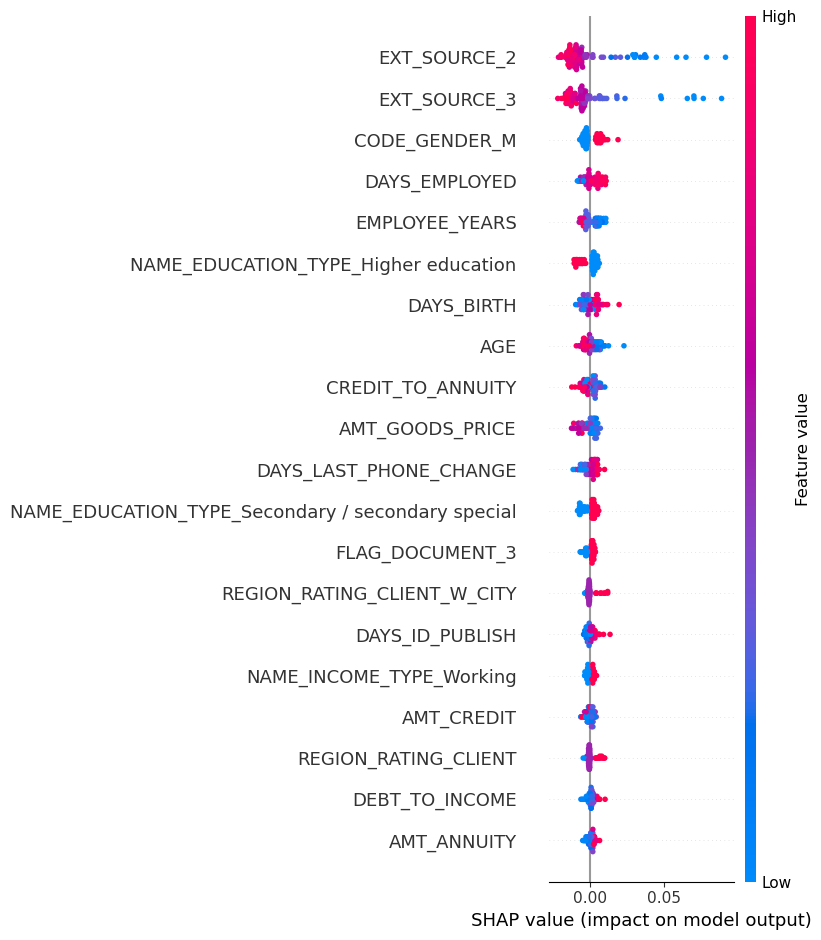

In [64]:
shap.summary_plot(shap_values[:,:,1], X_test[:100])